# Predicting Marketing Sales with a Decision Tree Regressor

Our question is simple: **given a planned promotion, what sales value should we expect?**

## Data source and an honest note

The accompanying file, `marketing_sales_data.csv`, is a local copy of Kaggle's [Marketing Promotion TV vs Radio vs Social Media](https://www.kaggle.com/datasets/yakhyojon/marketing-promotion) dataset (CC0). Kaggle describes each row as a marketing promotion using TV, radio, social-media, and influencer activity to increase sales.

This is a published **dataset snapshot**, not a live data feed. It is useful for learning campaign-level sales prediction. A full production marketing-mix model would usually also need a date/week, prices, promotions, seasonality, competitors, and lagged advertising effects.

## What you will learn

1. Load a real marketing dataset.
2. Separate the **clues** (features) from the **answer** (sales).
3. Train a small decision tree and read its rules.
4. See why each split reduces the spread of sales values.
5. Improve a tree with `GridSearchCV`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree

RANDOM_STATE = 42
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

## 1. Meet the data

Each row is one promotion. `Sales` is the number we want to predict. The other columns are clues:

- `TV`: TV promotion budget category: Low, Medium, or High.
- `Radio`: radio promotion budget.
- `Social Media`: social-media promotion budget.
- `Influencer`: influencer size: Mega, Macro, Micro, or Nano.
- `Sales`: sales produced by the promotion.

In [2]:
data = pd.read_csv('marketing_sales_data.csv')

print(f'Rows: {data.shape[0]}')
print(f'Columns: {data.shape[1]}')
display(data.head())

print('Missing values in each column:')
display(data.isna().sum().to_frame('Missing values'))

Rows: 572
Columns: 5


,TV,Radio,Social Media,Influencer,Sales
0,Low,3.52,2.29,Micro,55.26
1,Low,7.76,2.57,Mega,67.57
2,High,20.35,1.23,Micro,272.25
3,Medium,20.11,2.73,Mega,195.10
4,High,31.65,7.78,Nano,273.96


Missing values in each column:


,Missing values
TV,0
Radio,0
Social Media,0
Influencer,0
Sales,0


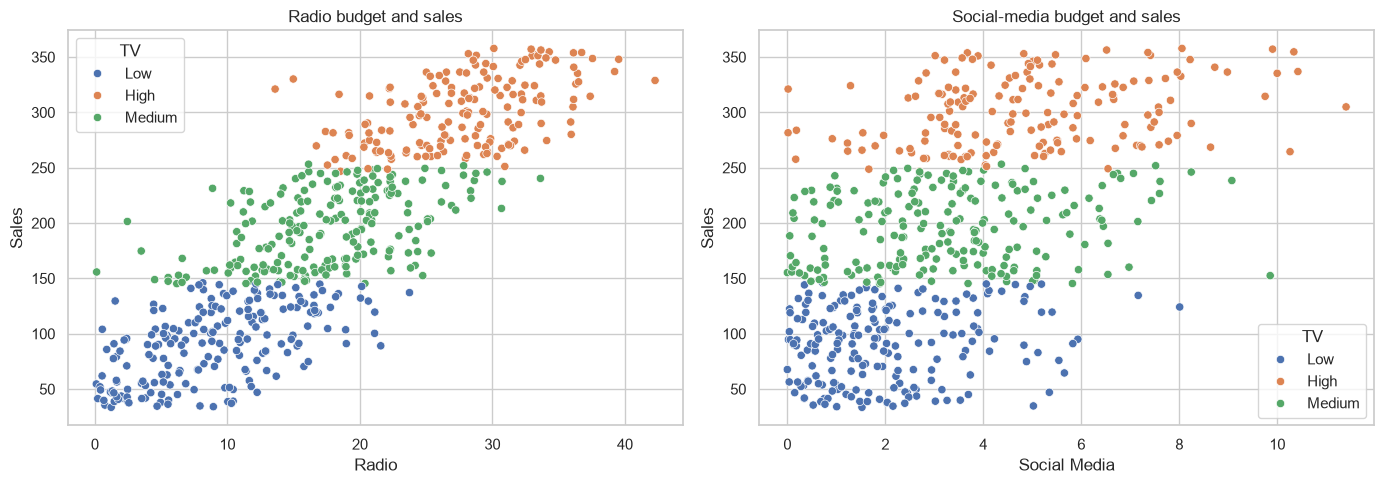

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(data=data, x='Radio', y='Sales', hue='TV', ax=axes[0])
axes[0].set_title('Radio budget and sales')

sns.scatterplot(data=data, x='Social Media', y='Sales', hue='TV', ax=axes[1])
axes[1].set_title('Social-media budget and sales')

plt.tight_layout()

## 2. Prepare the clues

A computer needs numbers. `TV` and `Influencer` are words, so `pd.get_dummies` changes them into yes/no columns. For example, `TV_High = 1` means that promotion used a high TV budget.

A decision tree does not need feature scaling. It only asks questions such as “Radio budget less than 16.5?”

In [4]:
X = data.drop(columns='Sales')          # clues
y = data['Sales']                       # answer we want to predict

X = pd.get_dummies(X, columns=['TV', 'Influencer'], dtype=int)

print('Columns used by the model:')
display(X.head())

Columns used by the model:


,Radio,Social Media,TV_High,TV_Low,TV_Medium,Influencer_Macro,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,3.52,2.29,0,1,0,0,0,1,0
1,7.76,2.57,0,1,0,0,1,0,0
2,20.35,1.23,1,0,0,0,0,1,0
3,20.11,2.73,0,0,1,0,1,0,0
4,31.65,7.78,1,0,0,0,0,0,1


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

print(f'Training examples: {len(X_train)}')
print(f'Test examples:     {len(X_test)}')
print('The test set is hidden from the model while it learns.')

Training examples: 429
Test examples:     143
The test set is hidden from the model while it learns.


## 3. Small helper functions

These helpers keep the rest of the notebook tidy. `visualize_tree` is intentionally simple: it uses scikit-learn's built-in drawing tool, so there is no Graphviz setup.

In [6]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    """Evaluate model performance on training and testing data."""

    # Make predictions
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Number of features
    p = X_train.shape[1]

    # R² scores
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    # Adjusted R²
    train_adj_r2 = 1 - (1 - train_r2) * (len(y_train) - 1) / (len(y_train) - p - 1)
    test_adj_r2 = 1 - (1 - test_r2) * (len(y_test) - 1) / (len(y_test) - p - 1)

    # Create results table
    scores = pd.DataFrame({
        'MAE': [
            mean_absolute_error(y_train, train_pred),
            mean_absolute_error(y_test, test_pred)
        ],
        'RMSE': [
            mean_squared_error(y_train, train_pred),
            mean_squared_error(y_test, test_pred)
        ],
        'R2': [train_r2, test_r2],
        'Adjusted R2': [train_adj_r2, test_adj_r2]
    }, index=['Train', 'Test'])

    display(scores)


def visualize_tree(model, feature_names, max_depth):
    """Draw the first few levels of a decision tree."""
    plt.figure(figsize=(20, 10))
    
    #Plot the decision tree: model = trained tree, 
    #feature_names = input feature labels, 
    #filled = color nodes by class/value, 
    #rounded = round node boxes, 
    #precision = decimal places shown, 
    #fontsize = text size, 
    #max_depth = maximum tree levels to display
    
    plot_tree(
        model, feature_names=feature_names, filled=True, rounded=True,
        precision=1, fontsize=9, max_depth=max_depth
    )
    plt.title(f'First {max_depth + 1} levels of the decision tree')
    plt.show()


def show_feature_importance(model, feature_names):
    """Show which clues the tree used most often to make helpful splits."""
    importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': model.feature_importances_
    }).sort_values('Importance', ascending=False)

    # display(importance.reset_index(drop=True))
    plt.figure(figsize=(8, 4))
    plt.barh(importance['Feature'], importance['Importance'], color='teal')
    plt.gca().invert_yaxis()
    plt.xlabel('Importance')
    plt.title('Which campaign clues helped the tree most?')
    plt.show()
    # return importance


def variance_reduction_table(model, feature_names):
    """Show the reduction in sales variance for every split in a tree."""
    tree = model.tree_
    rows = []

    for node in range(tree.node_count):
        left, right = tree.children_left[node], tree.children_right[node]
        if left == right:  # it is a leaf, so it does not split again
            continue

        parent_n = tree.n_node_samples[node]
        left_n, right_n = tree.n_node_samples[left], tree.n_node_samples[right]
        parent_variance = tree.impurity[node]
        child_variance = (
            (left_n / parent_n) * tree.impurity[left]
            + (right_n / parent_n) * tree.impurity[right]
        )
        rows.append({
            'Node': node,
            'Question asked': f'{feature_names[tree.feature[node]]} <= {tree.threshold[node]:.2f}',
            'Parent variance': parent_variance,
            'Weighted child variance': child_variance,
            'Variance reduced by': parent_variance - child_variance
        })

    return pd.DataFrame(rows)

## 4. How a tree makes a decision

Think of a tree as a game of “yes or no?” questions. At the start, sales values are spread out. A useful question puts similar sales values into the left and right groups.

**Variance** means “how spread out the sales numbers are.” A good split makes the weighted spread in the two child groups smaller than the spread in the parent group. The difference is called **variance reduction**.

We begin with a small tree so every rule can be read. `max_depth=3` means the tree may ask at most three questions in a row.

,MAE,RMSE,R2,Adjusted R2
Train,23.50,776.08,0.90,0.90
Test,25.47,877.96,0.89,0.88


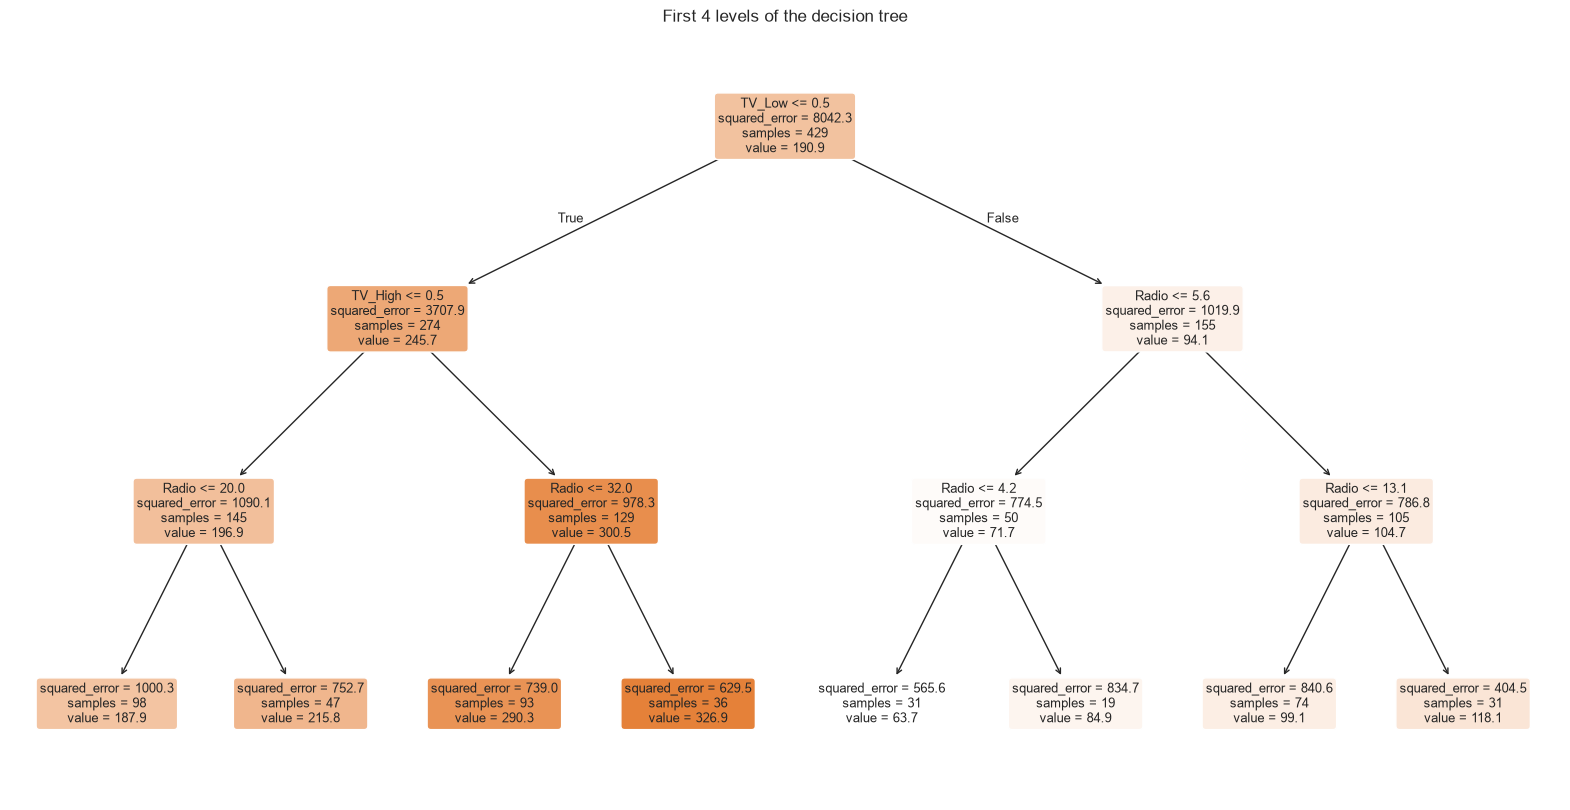

In [7]:
small_tree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=10, random_state=RANDOM_STATE)
small_tree.fit(X_train, y_train)

evaluate_model(small_tree, X_train, y_train, X_test, y_test)
visualize_tree(small_tree, X.columns, max_depth=3)

In [8]:
split_steps = variance_reduction_table(small_tree, X.columns)
display(split_steps.style.format({
    'Parent variance': '{:.2f}',
    'Weighted child variance': '{:.2f}',
    'Variance reduced by': '{:.2f}'
}))

print('Each row is one question the tree asked.')
print('Positive variance reduction means the split made the child groups more similar.')

,Node,Question asked,Parent variance,Weighted child variance,Variance reduced by
0,0,TV_Low <= 0.50,8042.30,2736.70,5305.60
1,1,TV_High <= 0.50,3707.89,1037.46,2670.42
2,2,Radio <= 19.95,1090.14,920.07,170.07
3,5,Radio <= 32.03,978.25,708.45,269.80
4,8,Radio <= 5.64,1019.89,782.79,237.10
5,9,Radio <= 4.25,774.46,667.82,106.64
6,12,Radio <= 13.09,786.75,711.88,74.88


Each row is one question the tree asked.
Positive variance reduction means the split made the child groups more similar.


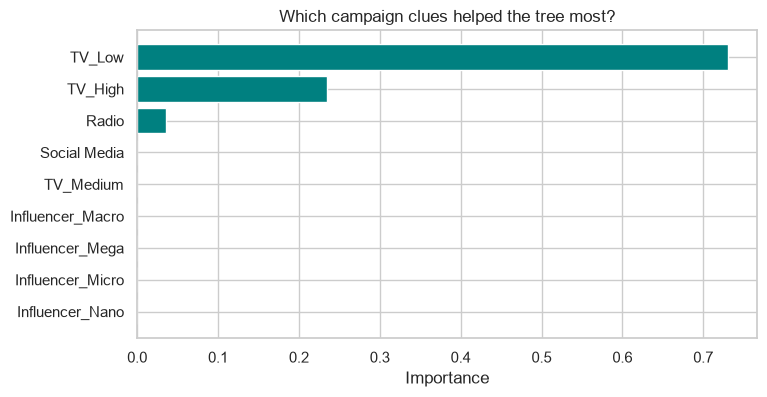

In [9]:
show_feature_importance(small_tree, X.columns)

## 5. Why tune a tree?

A tree with no limits can memorize the training data, including random noise. That often gives a very good training score but a worse test score.

We will tune three child-friendly controls:

- `max_depth`: how many questions can be asked in a row.
- `min_samples_split`: how many examples are needed before asking another question.
- `min_samples_leaf`: how many examples must be left in a final group.

`GridSearchCV` tries combinations using only the training data. It keeps the best combination, then we check it once with the unseen test data.

In [10]:
default_tree = DecisionTreeRegressor(random_state=RANDOM_STATE)
default_tree.fit(X_train, y_train)

print(f'Default tree depth: {default_tree.get_depth()}')
print(f'Default tree leaves: {default_tree.get_n_leaves()}')
evaluate_model(default_tree, X_train, y_train, X_test, y_test)

Default tree depth: 16
Default tree leaves: 429


,MAE,RMSE,R2,Adjusted R2
Train,0.00,0.00,1.00,1.00
Test,30.89,"1,528.50",0.81,0.80


In [11]:
split_steps = variance_reduction_table(default_tree, X.columns)
display(split_steps.style.format({
    'Parent variance': '{:.2f}',
    'Weighted child variance': '{:.2f}',
    'Variance reduced by': '{:.2f}'
}))

print('Each row is one question the tree asked.')
print('Positive variance reduction means the split made the child groups more similar.')

,Node,Question asked,Parent variance,Weighted child variance,Variance reduced by
0,0,TV_Low <= 0.50,8042.30,2736.70,5305.60
1,1,TV_High <= 0.50,3707.89,1037.46,2670.42
2,2,Radio <= 19.95,1090.14,920.07,170.07
3,3,Radio <= 13.87,1000.35,908.98,91.37
4,4,Social Media <= 3.61,746.69,658.95,87.74
5,5,Radio <= 10.24,874.60,573.76,300.84
6,6,Radio <= 2.97,581.43,466.84,114.59
7,8,Radio <= 7.88,505.74,407.24,98.51
8,9,Radio <= 4.00,85.82,6.07,79.75
9,11,Social Media <= 1.87,7.08,1.40,5.68


Each row is one question the tree asked.
Positive variance reduction means the split made the child groups more similar.


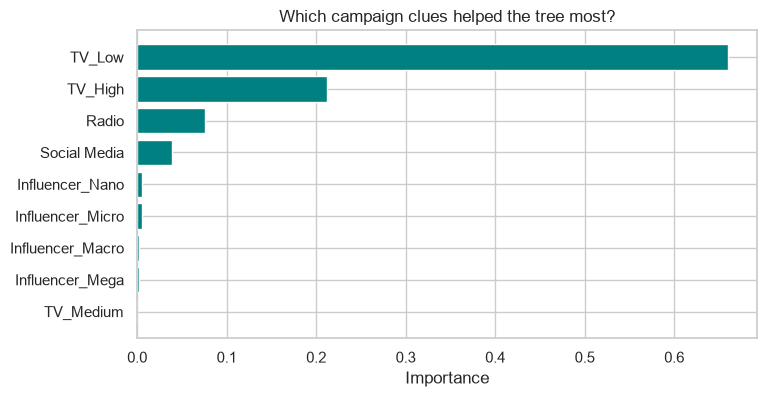

In [81]:
show_feature_importance(default_tree, X.columns)

# 6. GRID SEARCH CV

In [12]:
parameter_choices = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_split': [2, 10, 20, 30],
    'min_samples_leaf': [1, 3, 5, 10],
    'ccp_alpha': [0.0, 0.01, 0.05]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
    param_grid=parameter_choices,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_tree = grid_search.best_estimator_
print('Best settings:', grid_search.best_params_)
print(f'Best 5-fold CV RMSE: {-grid_search.best_score_:.2f}')
print(f'Best tree depth: {best_tree.get_depth()}')
print(f'Best tree leaves: {best_tree.get_n_leaves()}')

Best settings: {'ccp_alpha': 0.0, 'max_depth': 4, 'min_samples_leaf': 10, 'min_samples_split': 30}
Best 5-fold CV RMSE: 29.60
Best tree depth: 4
Best tree leaves: 15


Best tree results:


,MAE,RMSE,R2,Adjusted R2
Train,22.07,698.94,0.91,0.91
Test,24.20,842.56,0.90,0.89


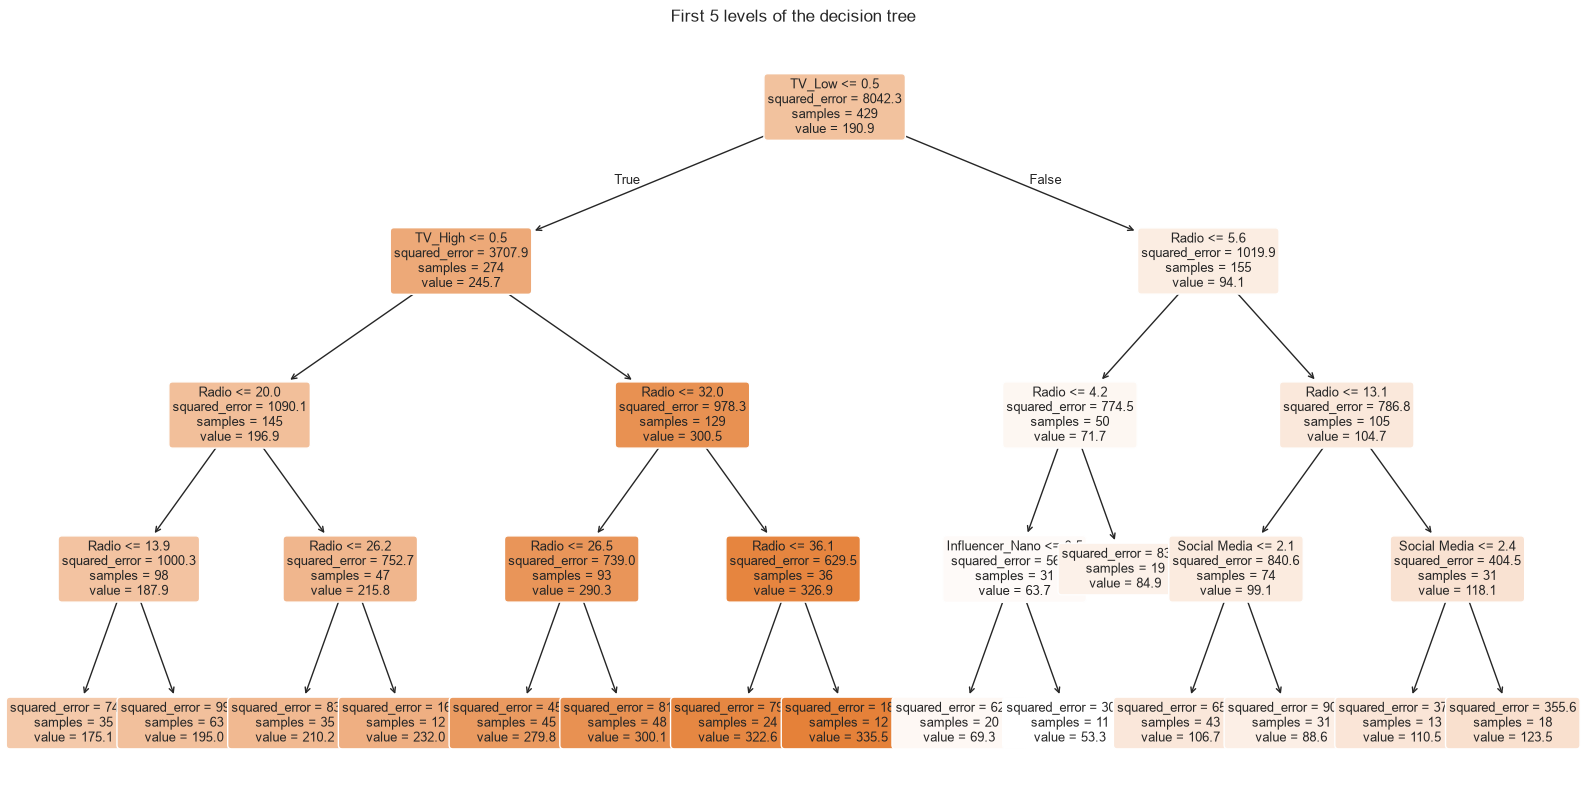

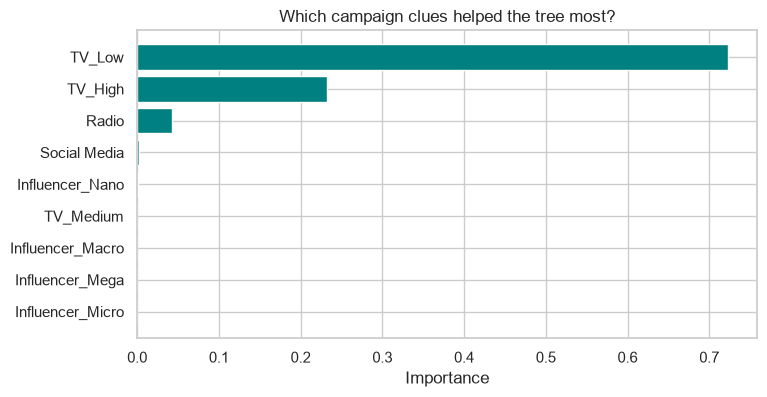

The final tree made 14 split decisions. Here is every one:


,Node,Question asked,Parent variance,Weighted child variance,Variance reduced by
0,0,TV_Low <= 0.50,8042.30,2736.70,5305.60
1,1,TV_High <= 0.50,3707.89,1037.46,2670.42
2,2,Radio <= 19.95,1090.14,920.07,170.07
3,3,Radio <= 13.87,1000.35,908.98,91.37
4,6,Radio <= 26.15,752.68,662.34,90.34
5,9,Radio <= 32.03,978.25,708.45,269.80
6,10,Radio <= 26.46,739.01,635.96,103.05
7,13,Radio <= 36.10,629.50,592.33,37.17
8,16,Radio <= 5.64,1019.89,782.79,237.10
9,17,Radio <= 4.25,774.46,667.82,106.64


In [13]:
print('Best tree results:')
best_tree_scores = evaluate_model(best_tree, X_train, y_train, X_test, y_test)

visualize_tree(best_tree, X.columns, max_depth=4)
show_feature_importance(best_tree, X.columns)

all_best_splits = variance_reduction_table(best_tree, X.columns)
print(f'The final tree made {len(all_best_splits)} split decisions. Here is every one:')
display(all_best_splits.style.format({
    'Parent variance': '{:.2f}',
    'Weighted child variance': '{:.2f}',
    'Variance reduced by': '{:.2f}'
}))

## Takeaways

- A decision tree predicts a number by splitting data into smaller, more similar groups.
- Each split is chosen because it reduces the spread (variance) of sales in its child groups.
- An unrestricted tree can remember too much. The default tree is much larger than the tuned tree.
- `GridSearchCV` helps select a smaller tree using training folds, not the test set.
- Always compare predictions on data the model did not see while learning.
- This dataset supports a beginner campaign-sales exercise. Do not treat its feature importance as proof that a channel caused sales; real MMM needs time and business controls.